In [ ]:
!apt-get install -y libta-lib0-dev

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
E: Unable to locate package libta-lib0-dev


In [ ]:
import yfinance as yf
import pandas as pd # Import pandas to use its functionalities

# Exemple : Récupérer les données historiques d'une action ou d'un indice
data = yf.download('BTC-USD', start="2020-11-20", end="2025-12-23")

# The following MultiIndex flattening logic is no longer necessary or is incorrect
# with the new default behavior of yfinance (auto_adjust=True).
# If yfinance returns a MultiIndex, the structure might be (Metric, Ticker)
# where get_level_values(0) would give the metric (Close, Open, etc.)
# but often, for a single ticker, the columns are already flat.
# Keeping only the relevant logic:

# Ensure columns are properly named in case of MultiIndex output from yfinance
# For single ticker, metric names are usually at level 0 of a (Metric, Ticker) MultiIndex
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

# Drop 'Adj Close' column if it exists (it's often merged into 'Close' with auto_adjust=True)
if 'Adj Close' in data.columns:
    data = data.drop(columns=['Adj Close'])

# Rename the index to 'Date' for clarity when saving/loading
data.index.name = 'Date'

print(data.head(20))

/tmp/ipython-input-870387942.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD', start="2020-11-20", end="2025-12-23")
[*********************100%***********************]  1 of 1 completed

Price              Close          High           Low          Open  \
Date                                                                 
2020-11-20  18621.314453  18773.226562  17765.794922  17817.083984   
2020-11-21  18642.232422  18936.621094  18444.359375  18621.316406   
2020-11-22  18370.001953  18688.968750  17671.384766  18642.232422   
2020-11-23  18364.121094  18711.425781  18000.796875  18370.017578   
2020-11-24  19107.464844  19348.271484  18128.656250  18365.015625   
2020-11-25  18732.121094  19390.964844  18581.146484  19104.410156   
2020-11-26  17150.623047  18866.285156  16351.035156  18729.839844   
2020-11-27  17108.402344  17445.023438  16526.423828  17153.914062   
2020-11-28  17717.414062  17853.939453  16910.652344  17112.933594   
2020-11-29  18177.484375  18283.628906  17559.117188  17719.634766   
2020-11-30  19625.835938  19749.263672  18178.322266  18178.322266   
2020-12-01  18802.998047  19845.974609  18321.921875  19633.769531   
2020-12-02  19201.09

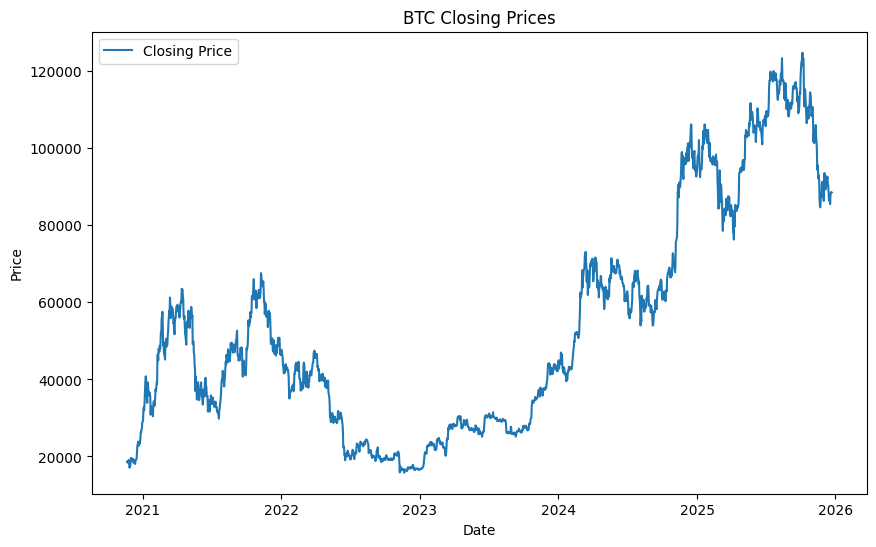

In [ ]:
# Visualiser les prix de clôture
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(data['Close'], label='Closing Price')
plt.title('BTC Closing Prices')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

In [ ]:
# Sauvegarder les données dans un fichier CSV
data.to_csv('BTC_historical_data.csv', index=True) # 'index=True' garde la colonne Date
print("Les dnes sauvegardées dans 'BTC_historical_data.csv'.")

Les dnes sauvegardées dans 'BTC_historical_data.csv'.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout

# Charger les données sans spécifier parse_dates ou index_col initialement
data = pd.read_csv('BTC_historical_data.csv')

# Si la première colonne n'est pas nommée 'Date', on la renomme et la définit comme index
# On suppose que la première colonne est celle des dates qui était l'index original
if data.columns[0] != 'Date':
    data.rename(columns={data.columns[0]: 'Date'}, inplace=True)

# Convertir 'Date' en format datetime et définir comme index
data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
data.set_index('Date', inplace=True)

# Vérifiez les colonnes
print("Colonnes disponibles :", data.columns)

Colonnes disponibles : Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


In [ ]:
# Vérifiez les valeurs non numériques dans la colonne 'Close'
print("Valeurs uniques dans 'Close' avant traitement :",
data['Close'].unique())
# Convertir 'Close' en numérique
data['Close'] = pd.to_numeric(data['Close'], errors='coerce')
# Supprimer les lignes avec des valeurs NaN
data = data.dropna(subset=['Close'])
# Ajout d'indicateurs techniques (moyennes mobiles)
data['SMA_10'] = data['Close'].rolling(window=10).mean()
data['SMA_30'] = data['Close'].rolling(window=30).mean()

Valeurs uniques dans 'Close' avant traitement : [18621.31445312 18642.23242188 18370.00195312 ... 88344.
 88621.75       88490.015625  ]


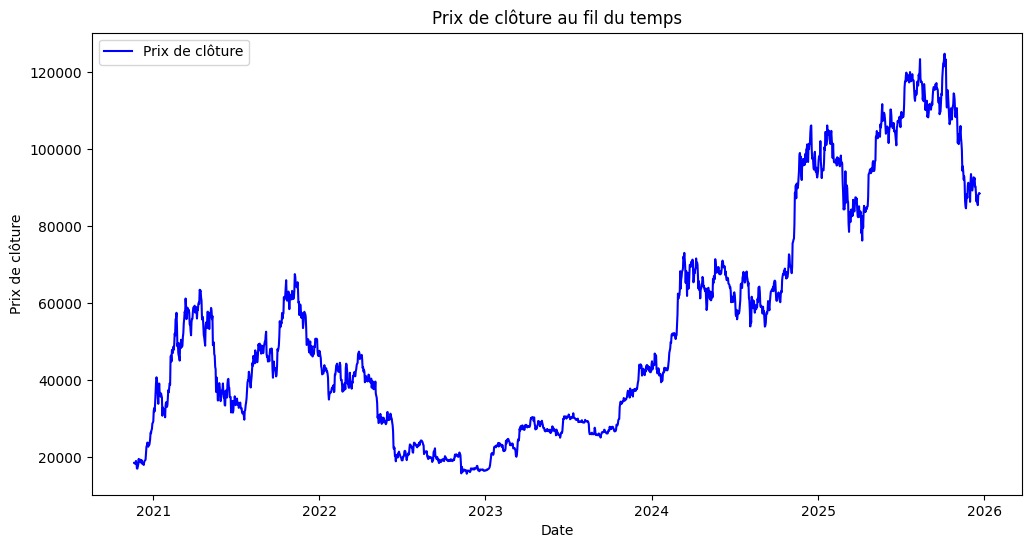

In [ ]:
# Supprimer les colonnes inutiles pour le scalage
data = data[['Close']] # Conserver uniquement la colonne 'Close'
# Visualisation des prix de clôture
plt.figure(figsize=(12, 6))
plt.plot(data['Close'], label='Prix de clôture', color='blue')
plt.title('Prix de clôture au fil du temps')
plt.xlabel('Date')
plt.ylabel('Prix de clôture')
plt.legend()
plt.show()

In [ ]:
# Mise à l'échelle des données
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data)

# Définition de la fenêtre temporelle
window_size = 60

X, y = [], []

for i in range(window_size, len(data_scaled)):
    X.append(data_scaled[i-window_size:i, 0])
    y.append(data_scaled[i, 0])

X, y = np.array(X), np.array(y)


# Création de l'axe temporel associé aux labels
dates = data.index
dates_y = dates[window_size:]

# Séparation Train / Test
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test  = X[train_size:]

y_train = y[:train_size]
y_test  = y[train_size:]

dates_test = dates_y[train_size:]

# Reshape pour LSTM
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test  = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)


In [ ]:
model = Sequential()

model.add(LSTM(50, return_sequences=True,
               input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))

model.add(LSTM(50))
model.add(Dropout(0.2))

model.add(Dense(1))

model.compile(optimizer='adam', loss='mean_squared_error')


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.0129 - val_loss: 0.0029
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0015 - val_loss: 0.0016
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0013 - val_loss: 0.0017
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0011 - val_loss: 0.0013
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0010 - val_loss: 0.0011
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 9.5295e-04 - val_loss: 0.0023
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 8.6650e-04 - val_loss: 0.0016
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 8.6733e-04 - val_loss: 0.0021
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 8.9660e-04 - val_loss: 0.0012
Epoch 12/100
36/36 ━━━━━━━━━━━━━━━━━

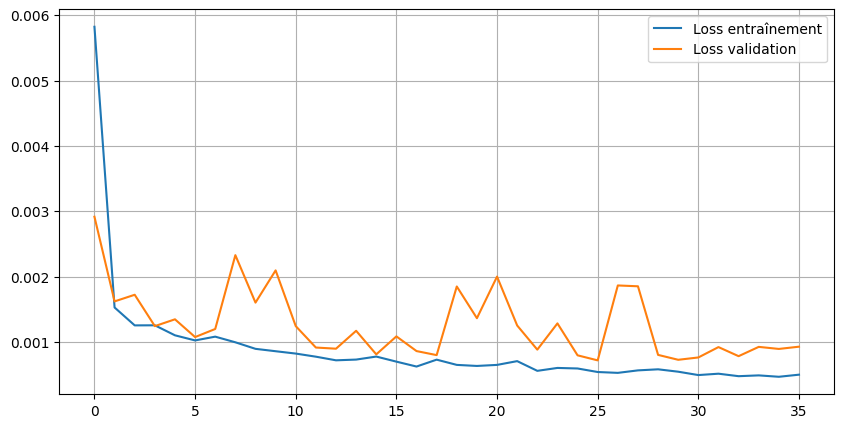

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Loss entraînement')
plt.plot(history.history['val_loss'], label='Loss validation')
plt.legend()
plt.grid()
plt.show()


In [ ]:
y_pred = model.predict(X_test)

# Retour à l’échelle réelle
y_pred = scaler.inverse_transform(y_pred)
y_test = scaler.inverse_transform(y_test.reshape(-1, 1))


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


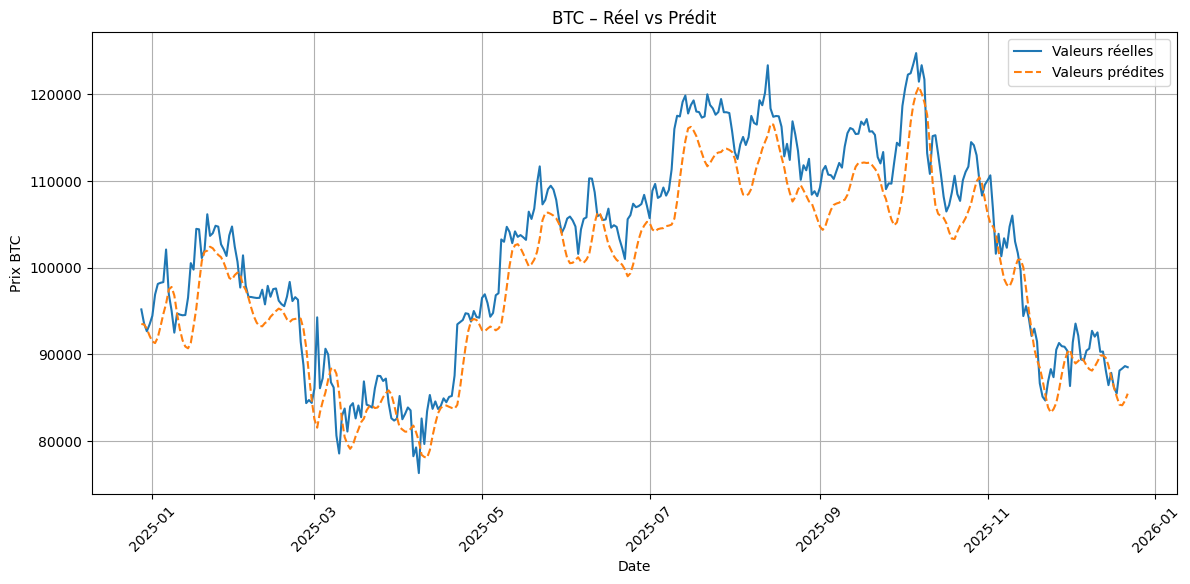

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(dates_test, y_test, label='Valeurs réelles')
plt.plot(dates_test, y_pred, label='Valeurs prédites', linestyle='--')

plt.xlabel("Date")
plt.ylabel("Prix BTC")
plt.title("BTC – Réel vs Prédit")
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.show()


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE :", mae)
print("RMSE :", rmse)

MAE : 3585.2665364583368
RMSE : 4288.470914862636


In [ ]:
n_future = 3
last_window = data_scaled[-window_size:].reshape(1, window_size, 1)

future_predictions = []

for _ in range(n_future):
    next_pred = model.predict(last_window)
    future_predictions.append(next_pred[0, 0])

    last_window = np.append(
        last_window[:, 1:, :],
        [[[next_pred[0, 0]]]],
        axis=1
    )

future_predictions = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


In [ ]:
last_date = data.index[-1]

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=n_future,
    freq='D'
)


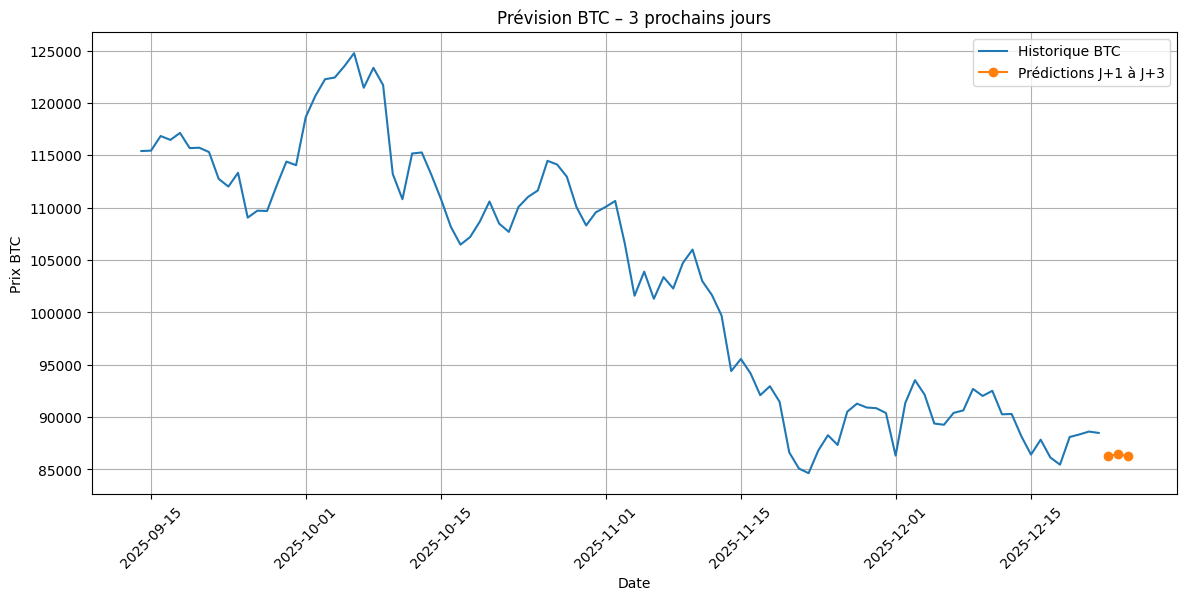

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(data.index[-100:], data['Close'][-100:], label='Historique BTC')
plt.plot(future_dates, future_predictions,
         label='Prédictions J+1 à J+3',
         marker='o')

plt.xlabel("Date")
plt.ylabel("Prix BTC")
plt.title("Prévision BTC – 3 prochains jours")
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.show()
